# DINGO: imaging reference and R+C MCMC

First inspect a calibrated F150W PySersic fit, then set the DINGO geometry and starting values yourself. The imaging block is a reference: it does not automatically set a gas center, inclination prior or velocity.

Use the **grism** kernel. The existing three-file R+C model is unchanged, with intrinsic dispersion zero. A numerical `fixed_x0`, `fixed_y0` or `fixed_inclination` holds that parameter fixed; `None` samples it with its stated prior. Corner plots contain only sampled parameters.

In [47]:
from pathlib import Path
import os
import sys
import logging
import importlib
import matplotlib.pyplot as plt
from IPython.display import display

# Change these paths on another computer. No saved fits are read from them.
REPO = Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
EDR_DIR = Path("/home/aakavan/EDR_data")
SOURCE_ID = 6170  # Used by both the imaging reference and DINGO
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
# Keep warnings visible; progress bars report the sampling steps.
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm
sm = importlib.reload(sm)

print("Code:", sm.__file__)
print("Output root:", OUTPUT_ROOT)

Code: /home/aakavan/kinematics/grism-kinematics/dingo/simple_mcmc.py
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 0. PySersic imaging reference

Like `master_run_Paalpha.ipynb`, this extracts **calibrated F150W SCI and ERR mosaic cutouts**. It fits one PSF-convolved Sérsic component with free index $n$ and a constant sky level. The nonlinear legacy `image.fits` is not fitted. The actual image appears before sampling; afterward, the image and model mark the fitted center with a cyan cross, followed by PySersic's standard corner plot and shape/inclination tables. Standalone center-coordinate numbers are hidden. The full native corner still includes its imaging parameters. No residual panel is displayed.

`IMAGING_CUTOUT_SIZE` is the native mosaic box width (101 pixels is approximately 3.03 arcsec). `IMAGING_FIT_RADIUS` controls the circular fitted region in arcseconds; reduce it if an edge neighbour contaminates the fit. Inclination is derived from axis ratio, and both $q_0=0$ and $q_0=0.2$ are reported.

Four PySersic chains run in a separate JAX worker with progress and checkpoints. Matching saved fits are reused. Set `REFIT_IMAGING=True` to make a fresh fit, including after changing the imaging settings; earlier fits are preserved. The coordinate-reference table is saved to a file without printing it. Native PySersic `corner.png` and `corner.pdf` are saved directly in the imaging `fit_NNN` directory. No result is automatically applied to DINGO.

Reusing F150W morphology for ID6170: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/morph_fits/F150W_reference/fit_001


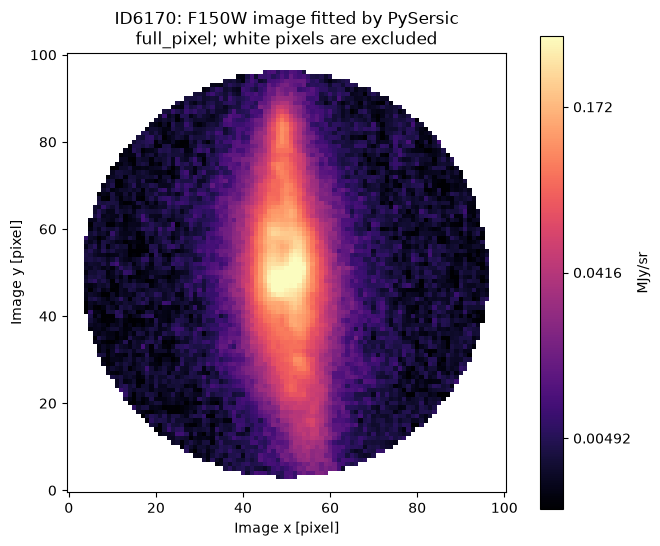

,fit,completed,ready,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,q_median,residual_RMS,parameter_checks_passed,note
0,full_pixel,True,True,1.001237,5161.096616,4702.859003,0,0.308206,2.420486,True,Inspect residuals; passing sampler checks does...


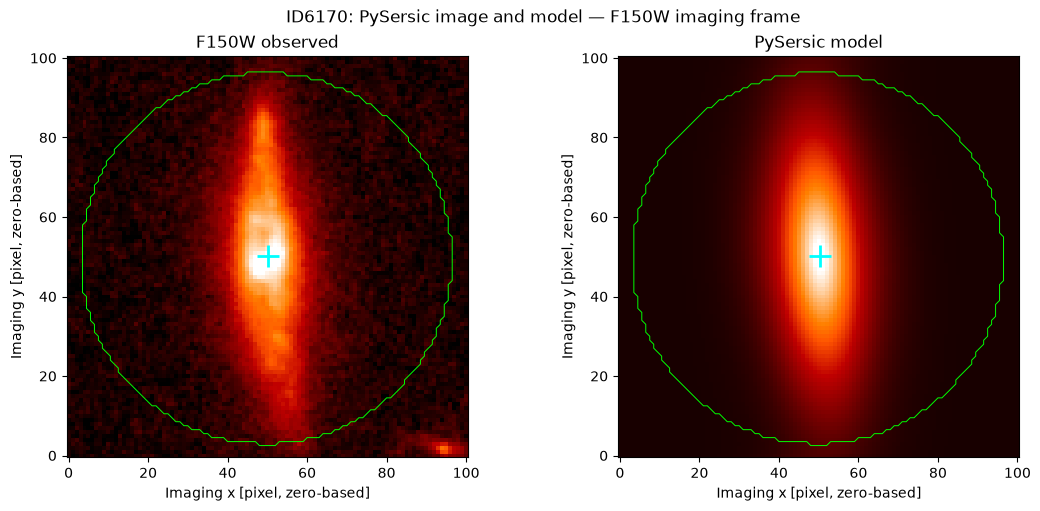

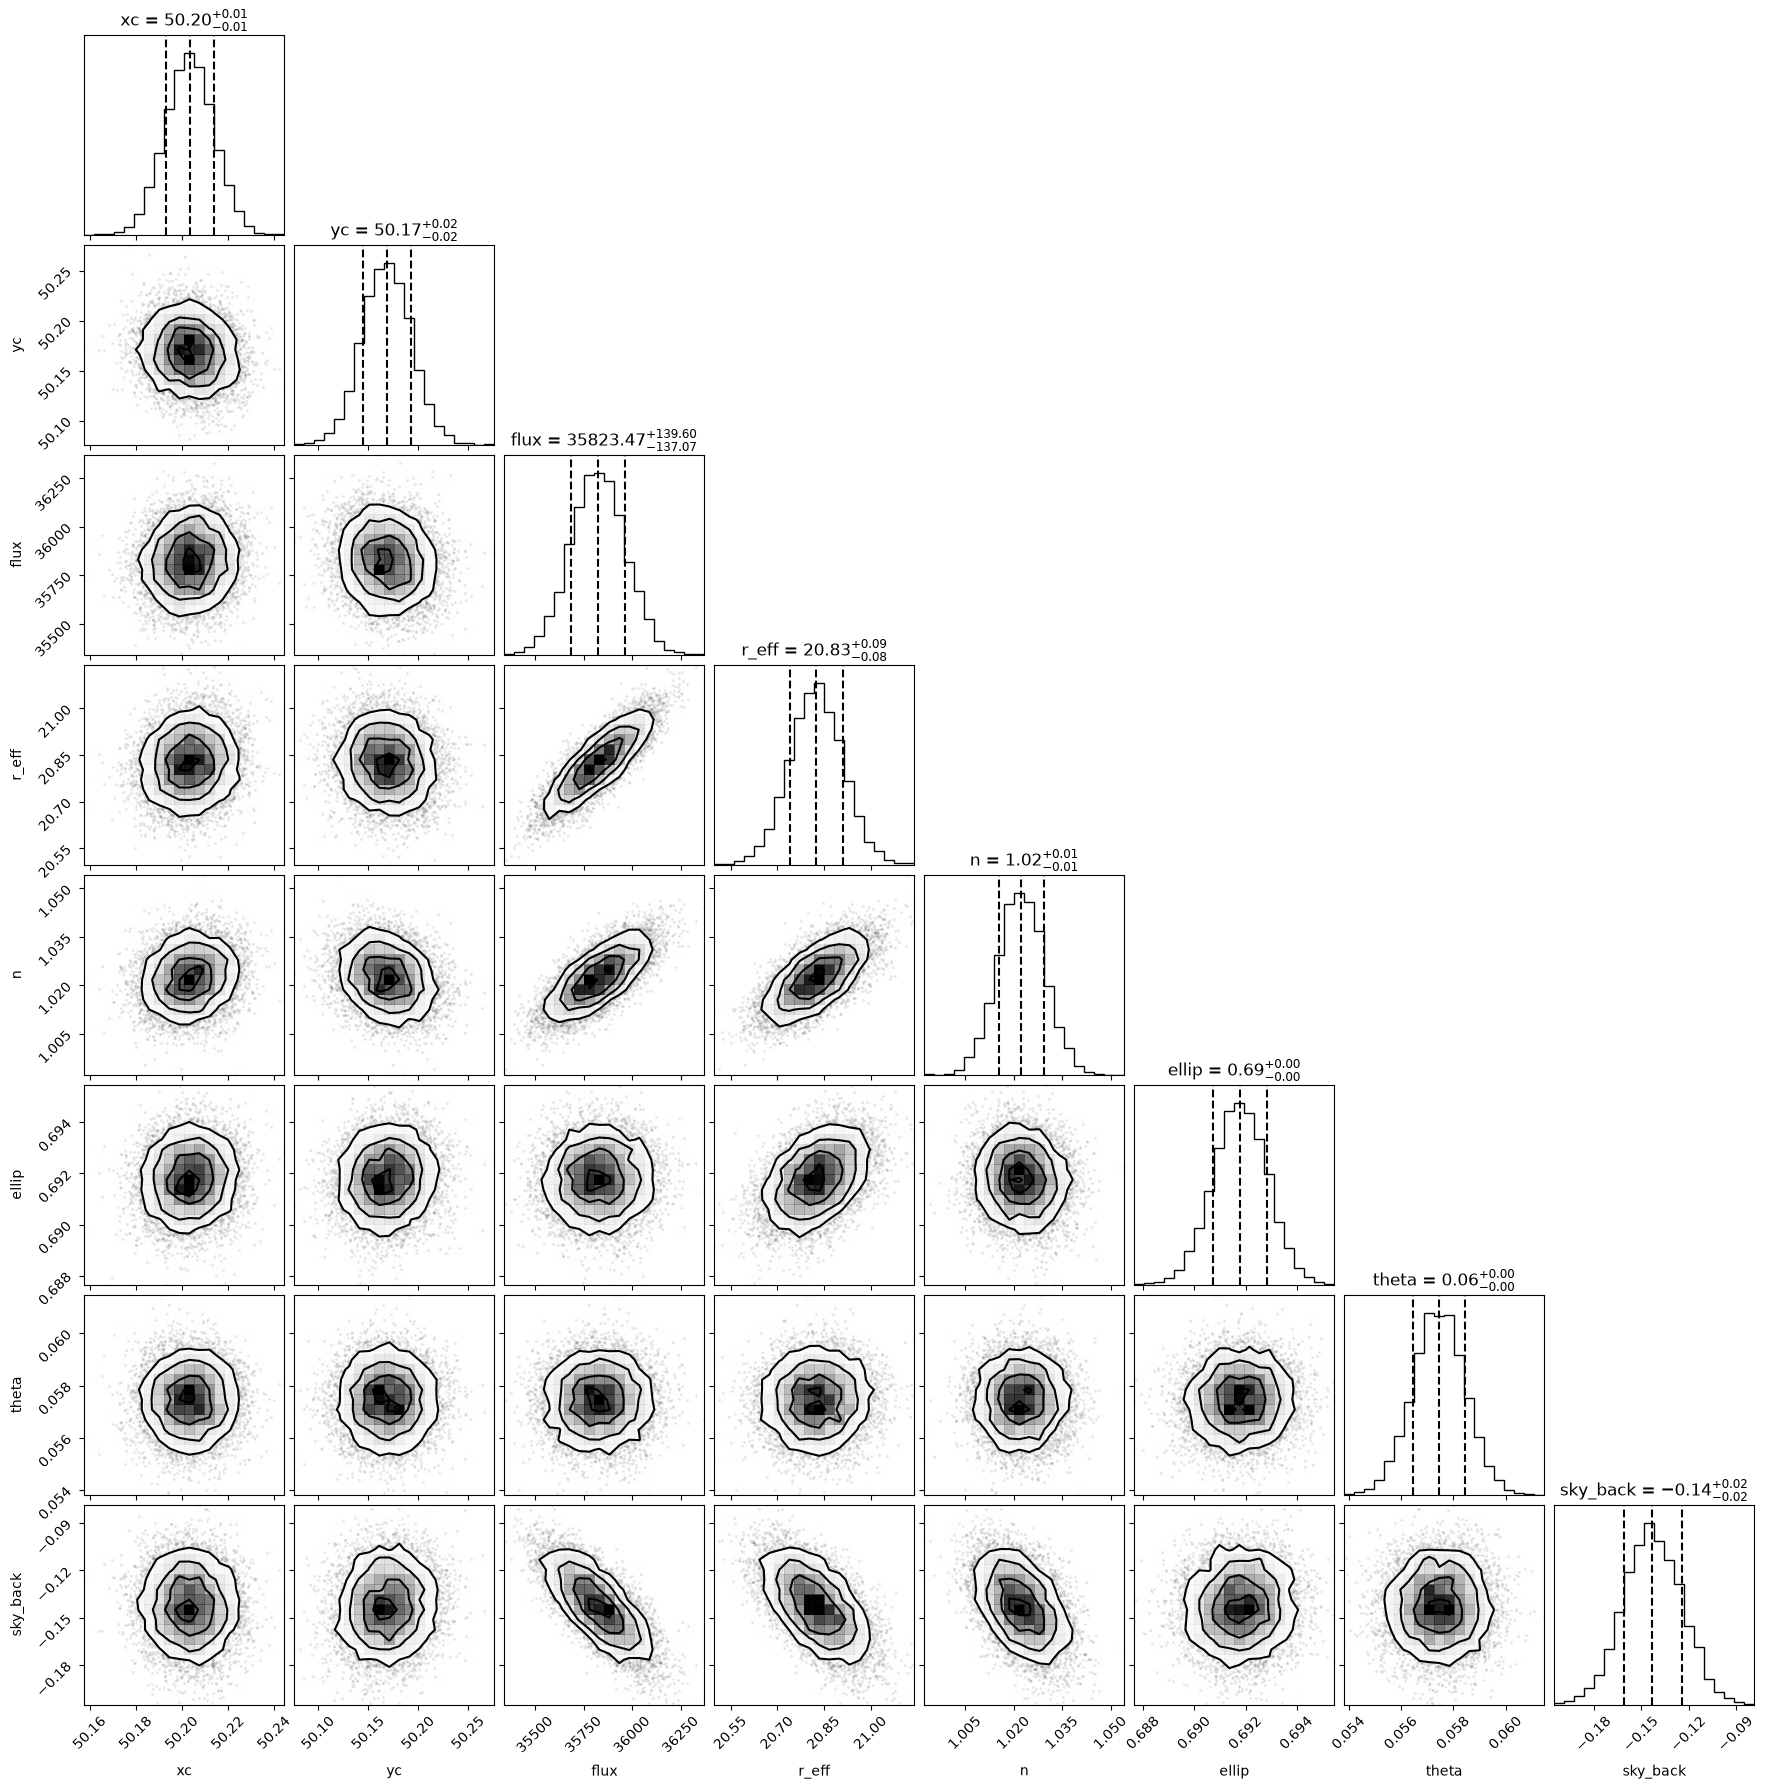

,meaning,median,minus_1sigma,plus_1sigma,p16,p84,unit
parameter,,,,,,,
flux,Total Sérsic flux,35823.469597,137.066669,139.601023,35686.402928,35963.070621,normalized image sum
r_eff,Effective radius,20.825110,0.083552,0.085355,20.741558,20.910465,pixel
n,Sérsic index,1.022392,0.007028,0.007064,1.015365,1.029456,
ellip,Ellipticity = 1 − b/a,0.691794,0.001050,0.001061,0.690745,0.692855,
theta,PySersic angle,0.057454,0.000987,0.000983,0.056467,0.058437,rad
sky_back,Constant sky level,-0.142980,0.017881,0.018824,-0.160861,-0.124155,normalized image value
q,Axis ratio b/a (derived),0.308206,0.001061,0.001050,0.307145,0.309255,
inclination_deg,"Stellar inclination (derived, q0=0)",72.048878,0.063245,0.063870,71.985633,72.112747,deg


,median_deg,minus_1sigma_deg,plus_1sigma_deg,incompatible_fraction,status
q0,,,,,
0.0,72.048878,0.063245,0.06387,0.0,compatible
0.2,76.152618,0.083020,0.08405,0.0,compatible


PySersic reference saved in: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/morph_fits/F150W_reference/fit_001
Imaging is a reference for your manual settings; no DINGO values or priors were changed.


In [48]:
from dingo import imaging_reference as ir, morphology, rotation_imaging
importlib.reload(rotation_imaging)
importlib.reload(morphology)
ir = importlib.reload(ir)

IMAGING_CUTOUT_SIZE = 101  # F150W mosaic pixels, not R/C pixels; use an odd width
IMAGING_FIT_RADIUS = 1.4   # Arcseconds; must fit inside the cutout
REFIT_IMAGING = False     # True makes a fresh PySersic fit; old fits are preserved

imaging = ir.fit_reference(
    SOURCE_ID,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    edr_dir=EDR_DIR,
    cutout_size=IMAGING_CUTOUT_SIZE,
    fit_radius=IMAGING_FIT_RADIUS,
    warmup=1000,
    draws=2000,
    device="cuda",       # Or "cpu"
    refit=REFIT_IMAGING,
    show_center_values=False,  # Hide standalone imaging-center coordinates
)

## 1. Choose DINGO geometry and starting values

This experiment **samples both center coordinates** with independent Gaussian priors:

$$x_0\sim\mathcal N(40,0.5^2),\qquad y_0\sim\mathcal N(40,0.5^2)$$

`CENTER_MEAN` sets the prior means in **R/C source-frame pixels**. `CENTER_SIGMA_PIXELS` sets each coordinate's standard deviation. It is a soft penalty, not a hard displacement limit. Set it to `1.0` for the wider comparison; the run name changes automatically. These widths are assumptions to test, not errors measured by PySersic.

`fixed_x0=None` and `fixed_y0=None` are required for these priors to matter. To fix the center instead, set those arguments to numbers; its Gaussian prior is then ignored. Inclination remains sampled with the explicit $75^\circ\pm5^\circ$ prior.

The settings below are manual. Imaging does not measure a rotation velocity or automatically set a gas center. `start_velocity` is the asymptotic $V_\infty$ starting value.

Products go to `OUTPUT_ROOT/source_ID/run_name/`. `overwrite=True` replaces only that named DINGO experiment. These comparison names differ from the previous fixed-center and Gaussian-center runs, which remain intact.

ID6170: explicit V_inf=450 km/s; initial i=75 deg; prior i=75 +/- 5 deg.
Saving to /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/center_fixed_x40.25_y40.62_i75_v450
Fixed: x0=40.25 px, y0=40.62 px. Excluded from optimization and MCMC; intervals are conditional on these values.
Sampled parameters: ['velocity.V_rot', 'velocity.R_v', 'velocity.theta_v', 'velocity.inc_v', 'image.R.dx', 'image.R.dy']


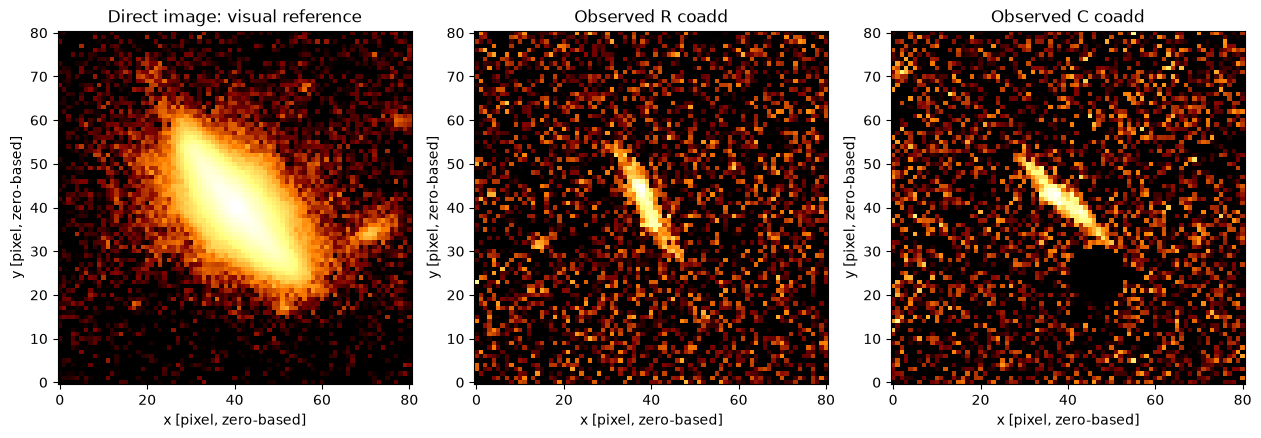

In [49]:
CENTER_MEAN = (40.0, 40.0)  # Assumed center in R/C stack pixels; check against the image
CENTER_SIGMA_PIXELS = 0.5    # 1-sigma in R/C pixels; change to 1.0 for comparison
# RUN_NAME = f"center_prior_s{CENTER_SIGMA_PIXELS:g}_i75_v450"
RUN_NAME = f"center_fixed_x40.25_y40.62_i75_v450"


run = sm.prepare(
    SOURCE_ID,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name=RUN_NAME,
    overwrite=True,
    device="cuda",                 # or "cpu"

    fixed_x0=40.25,                 # Sample x0; set 40.0 to hold it fixed instead
    fixed_y0=40.62,                 # Sample y0; set 40.0 to hold it fixed instead
    start_center=CENTER_MEAN,
    center_mean=CENTER_MEAN,
    center_sigma=CENTER_SIGMA_PIXELS,

    fixed_inclination=None,        # Sample i with the Gaussian prior below
    start_inclination=75.0,
    inclination_mean=75.0,
    inclination_sigma=5.0,         # 1-sigma, degrees

    start_velocity=450.0,          # Sampled V_inf, km/s
    start_turnover=10.09,          # Sampled R_t, pixels
    start_pa=286.64,               # Sampled cutout orientation, degrees
    start_offset=(1.0625, 0.2852),  # Sampled R registration dx,dy, pixels
    max_velocity=1000.0,
)
print("Sampled parameters:", run.fitter.mcmc_param_names)
fig = sm.show_inputs(run)
display(fig)
plt.close(fig)


## 2. Fit and inspect residuals

This optional local optimization fits the sampled parameters using the same posterior as MCMC. Any explicitly fixed coordinates remain fixed. The cyan cross marks the kinematic center. Skip `sm.fit_local(...)` to sample directly from your starting values.

Local fit evaluations:   0%|          | 0/3000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (87 evaluations).


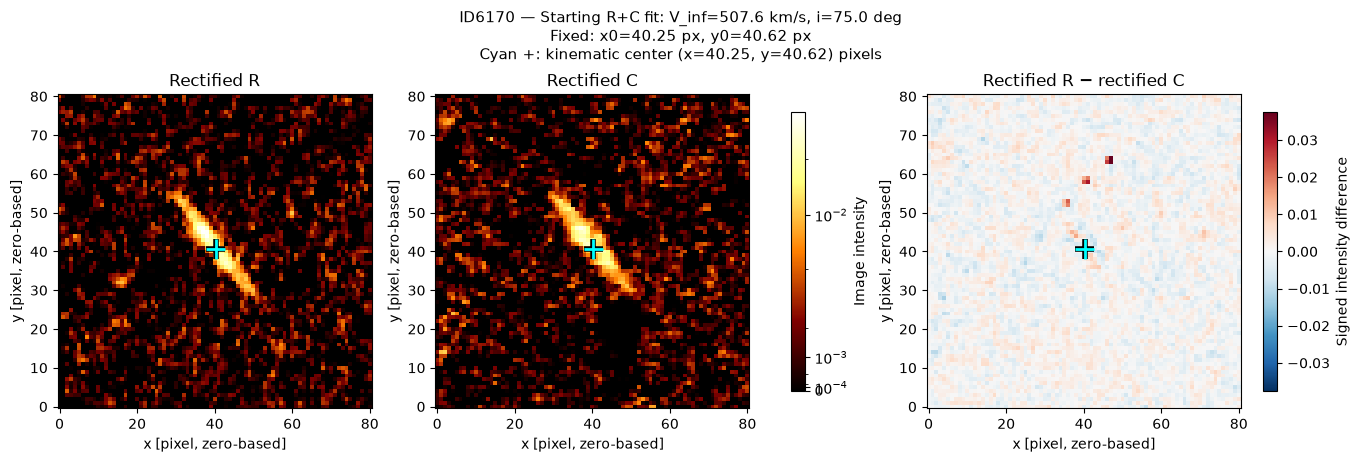

In [50]:
fit_status = sm.fit_local(run, max_evaluations=3000)
fig = sm.show_fit(run, label="Starting R+C fit")
display(fig)
fig.savefig(run.directory / "starting_fit.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## 3. Run MCMC

Edit the discarded `warmup`, retained `draws` per walker and `walkers` below. These are sampling budgets, not a guarantee of convergence: inspect all walkers and the diagnostics. For a quick execution check use `warmup=100, draws=200, walkers=32`.

Progress bars and checkpoints work as before. Sampling uses emcee with the PyTorch likelihood batched on the GPU.

In [51]:
RESULT_DIR = sm.sample(
    run,
    warmup=500,
    draws=2000,
    walkers=64,
    seed=42,
    progress="notebook",           # use True for a text progress bar
)
print(RESULT_DIR)

Warmup:   0%|          | 0/500 [00:00<?, ?it/s]

MCMC draws:   0%|          | 0/2000 [00:00<?, ?it/s]

The chain is shorter than 50 times the integrated autocorrelation time for 5 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 40;
tau: [97.30195469 97.39972103 96.78594494 63.50498577 69.47326971 31.63032772]


finished: 2000 retained steps per walker.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/center_fixed_x40.25_y40.62_i75_v450
/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/center_fixed_x40.25_y40.62_i75_v450


## 4. View saved results

The corner plot contains the sampled parameters. Fixed values are recorded with the saved results and omitted from the corner plot. The table gives pooled medians and 16–84% intervals. Residuals use one actual maximum-posterior sample.

To reopen results, run the imports and this cell with `RESULT_DIR` set below. Do not rerun preparation with `overwrite=True` merely to view results.

This block explicitly saves **`corner.png` and `corner.pdf` directly in `RESULT_DIR`**, alongside `samples.npz`. It can regenerate plots from a saved run without rerunning MCMC.

Status: finished; retained steps/walker: 2000; latest segment mean acceptance: 0.145
These are conditional posterior summaries. Check traces, bounds and independent starts before quoting errors.
Fixed: x0=40.25 px, y0=40.62 px. These quantities were not sampled; their uncertainty is not included.
Autocorrelation time per parameter: {'velocity.V_rot': 97.30195468865685, 'velocity.R_v': 97.3997210254056, 'velocity.theta_v': 96.78594493752772, 'velocity.inc_v': 63.504985767397045, 'image.R.dx': 69.47326971227389, 'image.R.dy': 31.630327721298187}
Corner plots saved directly in /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/center_fixed_x40.25_y40.62_i75_v450: corner.png and corner.pdf


,median,minus_16th,plus_84th,unit
parameter (all walkers pooled),,,,
V_inf,920.281512,76.158836,45.756203,km/s
R_t,27.920783,2.798859,1.762949,pixel
cutout_PA,296.163981,0.474945,0.415982,deg
inclination,76.451731,1.377114,0.824928,deg
R_x_offset,1.375303,0.079189,0.061867,pixel
R_y_offset,0.281564,0.015888,0.016090,pixel


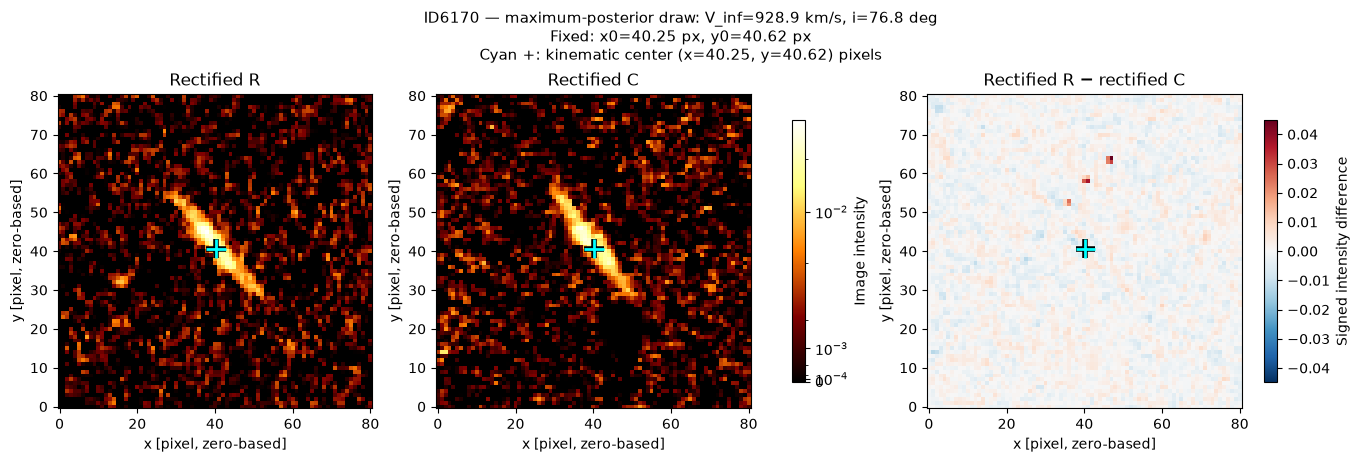

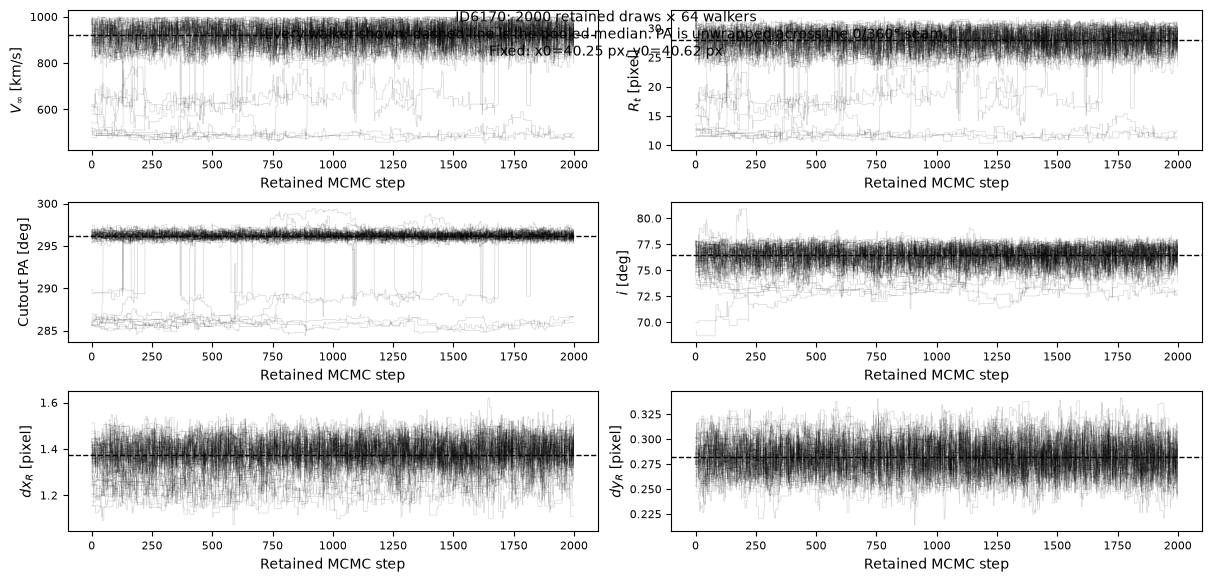

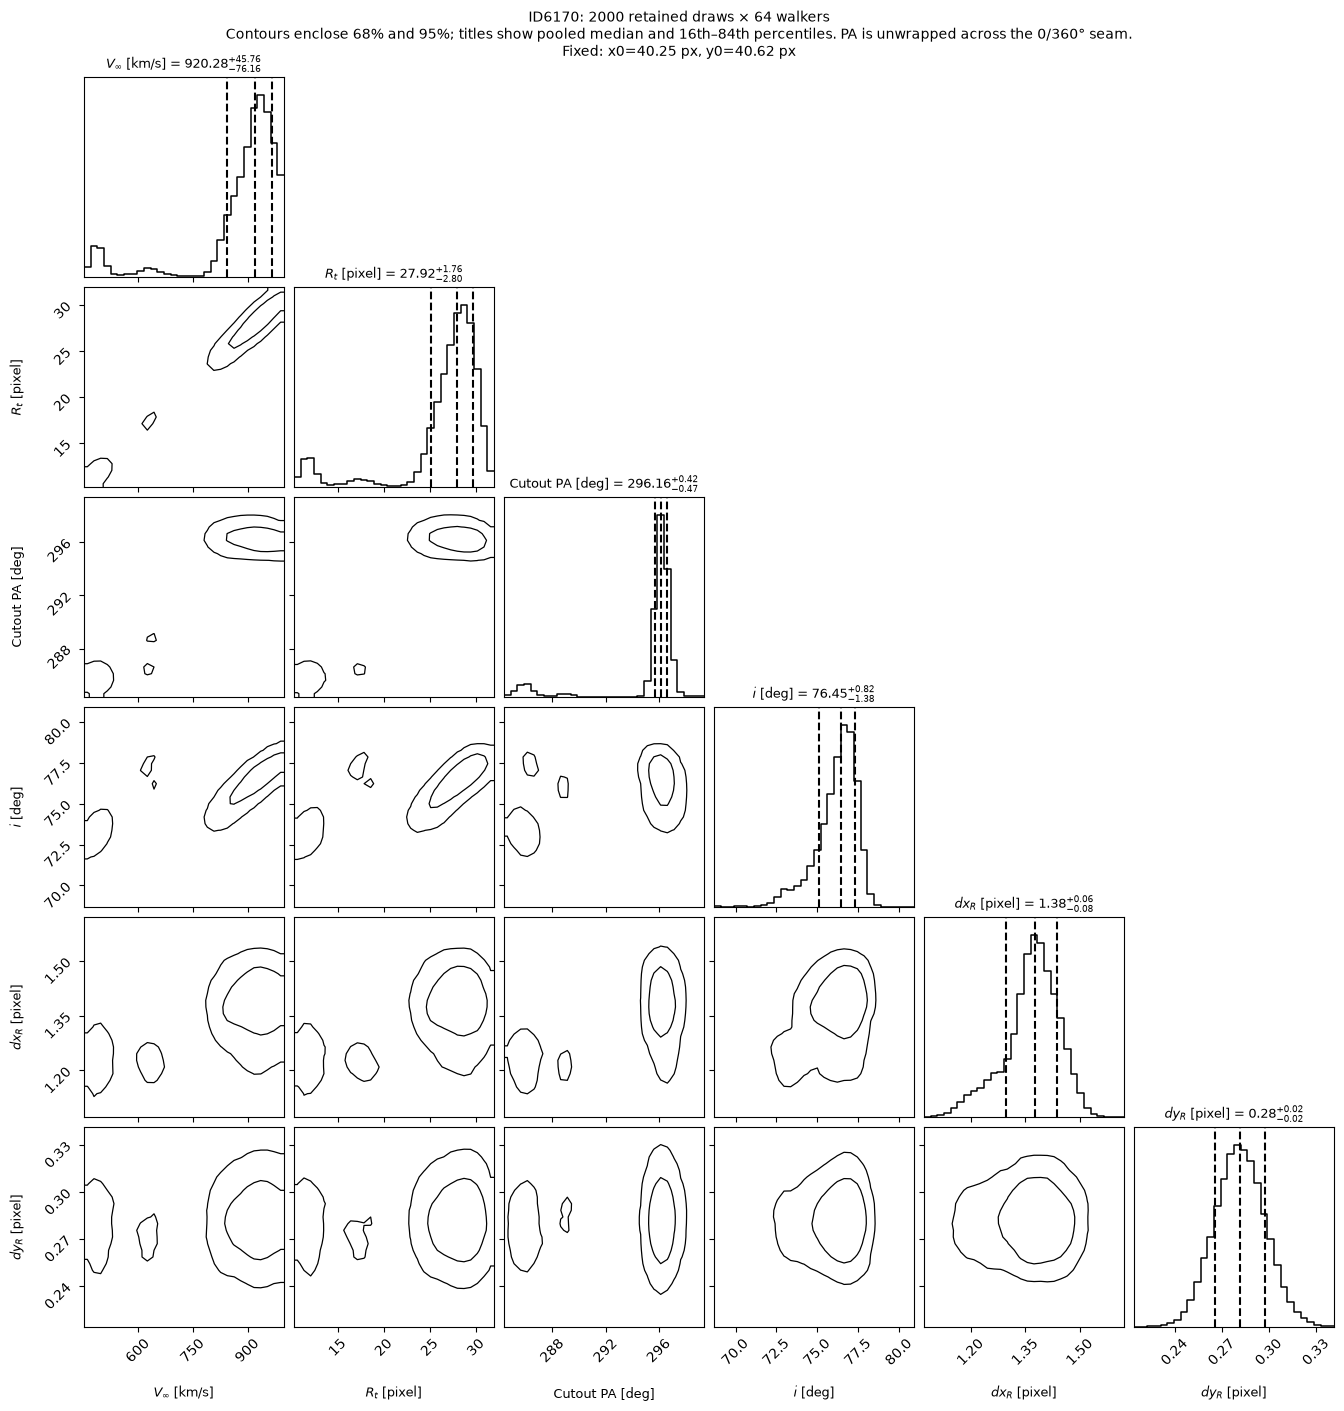

In [52]:
# To open saved results without fitting:
# RESULT_DIR = OUTPUT_ROOT / str(SOURCE_ID) / "center_prior_s0.5_i75_v450"
views = sm.show_results(RESULT_DIR, save=True)  # Writes corner.png and corner.pdf in this run folder
display(views["summary"])
for name in ("residuals", "traces", "corner"):
    display(views[name])
    plt.close(views[name])

The likelihood is the original full-image squared corrected R−C residual divided by a fixed noise variance estimated from the input stacks. This does not fully propagate coadd/interpolation covariance. Gaussian priors on free center coordinates and inclination are applied in both local fitting and MCMC; fixed parameters have no sampled prior. Settings are saved in `run_info.txt` and `config.yaml`.

The remaining priors are uniform $V_\infty$ from 0 to `max_velocity`, log-uniform turnover radius from 0.5 pixels to the cutout half-width, full-turn uniform orientation, and Gaussian R registration offsets about zero with width 2 pixels (truncated at ±10). These registration offsets are separate from the kinematic center. Inclination is restricted to 5–85 degrees, and center coordinates retain the existing bounds of ±30 pixels around the cutout midpoint.

A velocity piling up at its bound is still not a measured plateau speed. Inspect residuals, traces and independent starting points before quoting uncertainties.

Results are saved in `OUTPUT_ROOT/source_ID/run_name/`. To resume after a kernel restart: `run = sm.open_run(saved_directory)`, then `sm.sample(run, warmup=500, draws=8000, walkers=64, resume=True, progress="notebook")`. Keep the saved warmup and walker count; `draws` is the desired total retained length. A different center prior requires a separate experiment, not a resume of the previous chain.


## 5. Convert the saved run to physical units

**These new blocks only read the saved posterior; they do not run optimization or MCMC.** `RESULT_DIR` is the folder selected above. After a kernel restart, set it to the saved run you want before using these blocks.

Redshift is read from this run's saved source metadata. We use **Planck18 angular-diameter distances**, giving proper pc per arcsecond. The R/C FITS cutouts do not contain a pixel scale, so declare the scale of the **R/C stacks**, not the SW imaging used by PySersic. The current native LW cutouts use the adopted value **0.063 arcsec/pixel**. Change it for resampled data.

$$R_t[\mathrm{pc}]=R_t[\mathrm{pixel}]\,s[\mathrm{arcsec/pixel}]\,\mathrm{scale}(z)[\mathrm{pc/arcsec}].$$

Redshift, cosmology and pixel scale are treated as fixed. No lensing correction is applied.

In [53]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from dingo.simple_mcmc_profiles import PhysicalProfiles

# If reopening saved results, set this to your run folder:
# RESULT_DIR = Path("/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_v450")
PIXEL_SCALE_ARCSEC = 0.063  # R/C stack scale; do not substitute the F150W imaging scale
physical = PhysicalProfiles(RESULT_DIR, pixel_scale_arcsec=PIXEL_SCALE_ARCSEC)
print(f"ID{physical.source_id}: z = {physical.scale['redshift']:g}; {physical.scale['cosmology']}")
print(f"1 arcsec = {physical.scale['pc_per_arcsec']:,.2f} pc")
print(f"1 R/C pixel = {physical.scale['pc_per_pixel']:,.2f} pc")
print("Reading saved results from:", RESULT_DIR)

ID6170: z = 1.1147; Planck18
1 arcsec = 8,416.91 pc
1 R/C pixel = 530.27 pc
Reading saved results from: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/center_fixed_x40.25_y40.62_i75_v450


## 6. Velocity at the turnover radius, and turnover radius in parsecs

For this arctangent model, **$V(R_t)=V_\infty/2$ exactly**. We compute that velocity and $R_t$ in pc separately for every posterior draw, then report the pooled median and 16th–84th percentile offsets. The velocity is evaluated at **each draw's own turnover radius**, not at the median turnover radius.

The turnover radius may lie outside the well-measured emission. These are model-derived quantities. This configuration propagates the sampled center and inclination uncertainty under the stated priors; fixing a parameter instead excludes its uncertainty.

In [54]:
turnover = physical.turnover_summary(save=True)
display(turnover)

,median,minus_16th,plus_84th,unit
parameter,,,,
turnover_velocity,460.140756,38.079418,22.878101,km/s
turnover_radius_pixels,27.920783,2.798859,1.762949,pixel
turnover_radius_pc,14805.429906,1484.138304,934.831213,pc


## 7. Rotation curve in physical units

At each common radius, evaluate every paired $(V_\infty,R_t)$ posterior draw before taking percentiles. This preserves their correlation; it is different from inserting two marginal medians into the equation.

The line is the median, the band is the **pointwise 16th–84th percentile interval**, and the vertical marker is the median turnover radius when it falls within the displayed range. `MAX_RADIUS_PIXELS` sets a plotting range, **not a measured emission boundary**; the outer curve can be extrapolated. All velocities are already deprojected.

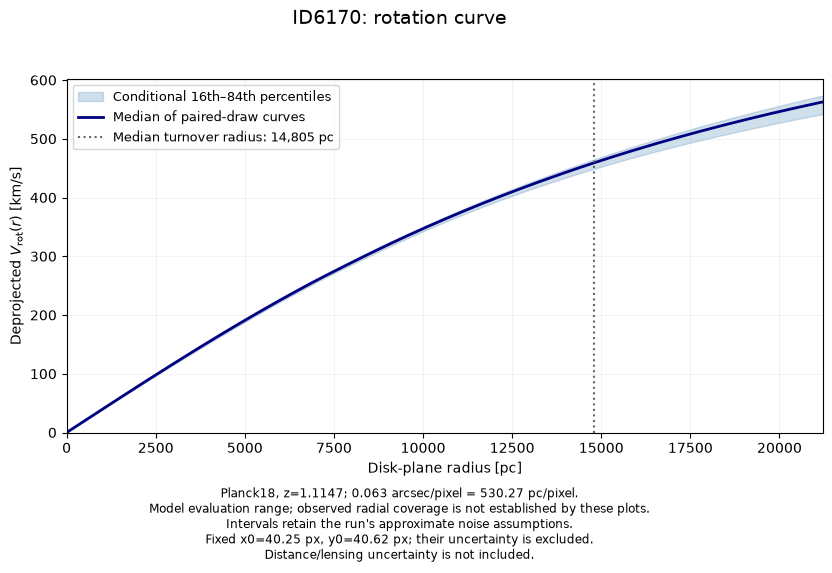

In [55]:
MAX_RADIUS_PIXELS = 40.0  # Display range only; adjust after assessing emission coverage
radii_pc = np.linspace(0.0, MAX_RADIUS_PIXELS * physical.scale["pc_per_pixel"], 161)
fig = physical.rotation_curve(radii_pc, save=True)
display(fig)
plt.close(fig)

## 8. Enclosed dynamical-mass estimate

Use the rotation speed **at each radius**, rather than inserting $V_\infty$ everywhere:

$$M_{\mathrm{dyn,sph}}(<r)=\frac{r\,V_{\mathrm{rot}}(r)^2}{G}.$$

This is a **rotation-only, spherical-equivalent enclosed-mass estimate**: it assumes rotation traces circular support and uses the spherical conversion from speed to enclosed mass. It includes no pressure-support, disk-geometry, or lensing correction. We calculate it for every posterior draw before taking percentiles. The band propagates uncertainty in the parameters actually sampled. It excludes uncertainty in redshift, pixel scale and any parameters you explicitly fix, if you choose a fixed center.

The outer mass curve is also extrapolated wherever the emission does not constrain the rotation curve. The new plots, turnover table and `physical_profiles.npz` are saved in the same run folder; existing samples and fit settings are unchanged.

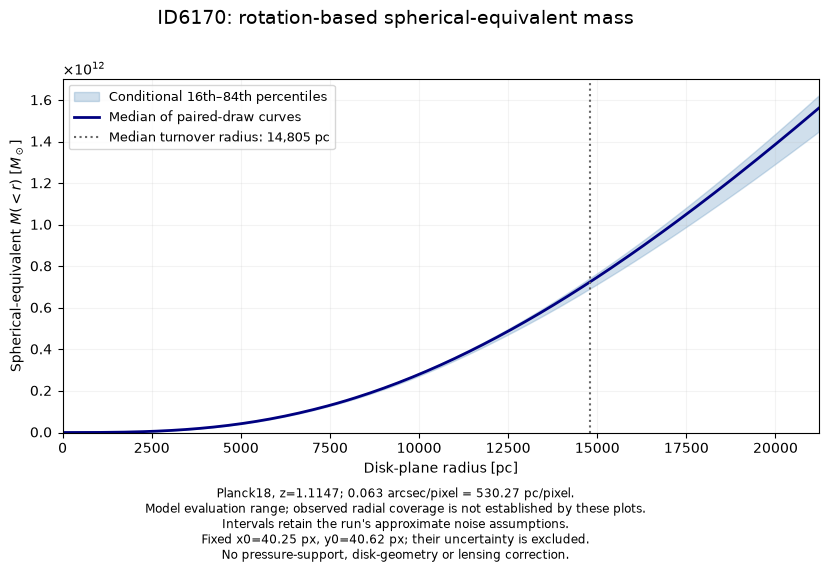

Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/center_fixed_x40.25_y40.62_i75_v450


In [56]:
fig = physical.mass_profile(radii_pc, save=True)
display(fig)
plt.close(fig)
print("Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to:", RESULT_DIR)